# How many $\theta_i$'s are there? Counting and spacing the Riemann spectrum

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part III, chapters "How many $\theta_i$'s are there?" and "Further questions about the Riemann spectrum".*

> The Riemann spectrum, $\theta_1, \theta_2, \theta_3, \dots$ clearly deserves to be well understood! What do we know about this sequence of positive real numbers?

In this notebook you will count the numbers of the Riemann spectrum (the imaginary parts of the zeros $\tfrac12 + i\theta$ of $\zeta(s)$), compare their staircase with the smooth curve that predicts it, compute $\theta_1$ to many digits, and look at the gaps between them, which behave like the eigenvalues of a random matrix and nothing like the gaps between primes.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
GAMMA = np.array([float(line) for line in open('zeta_zeros_1000.txt') if not line.startswith('#')])
print(len(GAMMA), 'numbers of the Riemann spectrum, up to', GAMMA[-1])

def smooth_count(T):
    "The smooth curve T/(2 pi) log(T/(2 pi e)) that the staircase of the Riemann spectrum follows."
    return T / (2 * np.pi) * np.log(T / (2 * np.pi * np.e))

1000 numbers of the Riemann spectrum, up to 1419.422480946


## 1. The staircase of the Riemann spectrum

> Just as we did with the prime numbers before, we can count these numbers $\theta_1=14.1347\ldots$, $\theta_2=21.0220\ldots$, etc., and form the staircase … with a step up at $\theta_1$, a step up at $\theta_2$, etc. … In fact, we know, conditional on RH, the staircase of real numbers $\theta_1, \theta_2, \theta_3,\dots$ is very closely approximated by the curve
$$\frac{T}{2\pi}\log \frac{T}{2\pi e},$$
> (the error term being bounded by a constant times $\log T$).

Look at the staircase from close up and from far away:

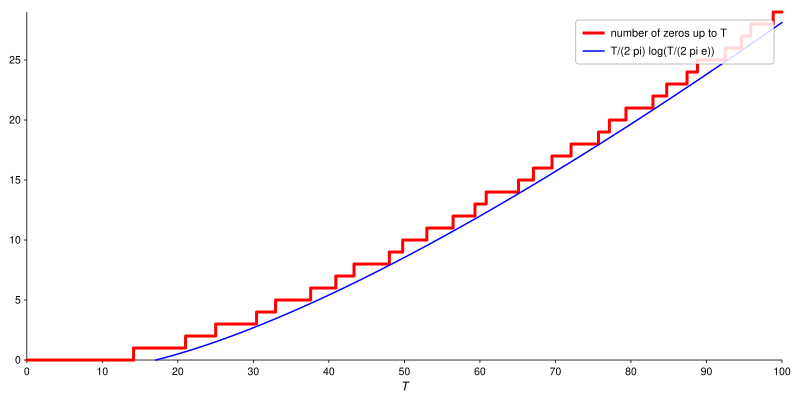

In [2]:
@interact
def spectrum_staircase(T=selector([30, 50, 100, 300, 1000, 1400], default=100, label='T up to'),
                       curve=checkbox(True, label='show the smooth curve')):
    z = GAMMA[GAMMA <= T]
    steps = [(0, 0)]
    for k, t0 in enumerate(z):
        steps += [(t0, k), (t0, k + 1)]
    steps.append((T, len(z)))
    g = line(steps, color='red', thickness=2, legend_label='number of zeros up to T')
    if curve:
        t = np.linspace(2 * np.pi * np.e, T, 500)
        g += list_plot(list(zip(t, smooth_count(t))), plotjoined=True, color='blue', legend_label='T/(2 pi) log(T/(2 pi e))')
    show(g, figsize=[8, 4], axes_labels=['$T$', ''])

## 2. What is left over

The difference between the staircase and the smooth curve wiggles around a constant ($\tfrac78$, from the next term of the Riemann–von Mangoldt formula) and stays small; it is known to be $O(\log T)$. Compare it with $\log T$ below. (This difference, which jumps up by $1$ at each $\theta_k$, is how computers check that no zero has been missed when they verify the Riemann Hypothesis up to some height.)

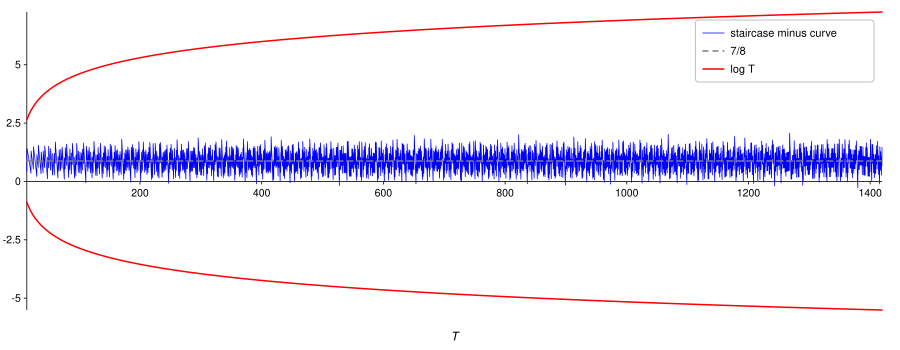

In [3]:
T = np.linspace(14, GAMMA[-1], 6000)
N = np.searchsorted(GAMMA, T, side='right')
left_over = N - smooth_count(T)
g = list_plot(list(zip(T, left_over)), plotjoined=True, color='blue', thickness=0.5, legend_label='staircase minus curve')
g += line([(14, 7/8), (T[-1], 7/8)], color='gray', linestyle='--', legend_label='7/8')
g += list_plot(list(zip(T, np.log(T))), plotjoined=True, color='red', legend_label='log T')
g += list_plot(list(zip(T, 1.75 - np.log(T))), plotjoined=True, color='red')
show(g, figsize=[9, 3.5], axes_labels=['$T$', ''])

## 3. $\theta_1$ to many digits

> Nowadays, these mysterious numbers $\theta_i$, these spectral lines for the staircase of primes, are known in great abundance and to great accuracy. Here is the smallest one, $\theta_1$, given with over $1{,}000$ digits of its decimal expansion:
>
> $14.134725141734693790457251983562470270784257115699243175685567460149\ldots$

Compute it yourself with mpmath, to as many digits as you like (each digit costs a little more time):

In [4]:
import mpmath

@interact
def theta_1(digits=selector([20, 50, 100], default=50, label='digits')):
    mpmath.mp.dps = digits + 5
    t1 = mpmath.zetazero(1).imag
    mine = mpmath.nstr(t1, digits)
    book = '14.134725141734693790457251983562470270784257115699243175685567460149' + '9634298092567649490103931715610127792029715487974367661426914698822545'
    print('computed: ', mine)
    print('the book: ', book[:len(mine)])

computed:  14.134725141734693790457251983562470270784257115699
the book:  14.134725141734693790457251983562470270784257115699


## 4. The gaps between the $\theta_i$'s

> In analogy with the discussion of prime gaps …, we might compute *pair correlation functions* and the statistics of gaps between successive $\theta$'s in the Riemann spectrum … This study was begun by H. L. Montgomery and F. J. Dyson. As Dyson noticed, the distributions one gets from the Riemann spectrum bears a similarity to the distributions of eigenvalues of a random unitary matrix.

Near height $T$ the average gap is $2\pi / \log(T/2\pi)$, so divide each gap by it: the normalized gaps have average $1$. If the $\theta$'s were independent random points (like Cramér's model of the primes, notebook *Gaps between primes*), the normalized gaps would follow the exponential density $e^{-s}$, with many tiny gaps. Instead they follow, very nearly, the gap law of eigenvalues of large random matrices (the "Wigner surmise" $\frac{32}{\pi^2}s^2 e^{-4s^2/\pi}$ approximates it): the zeros **repel** each other, and tiny gaps are rare.

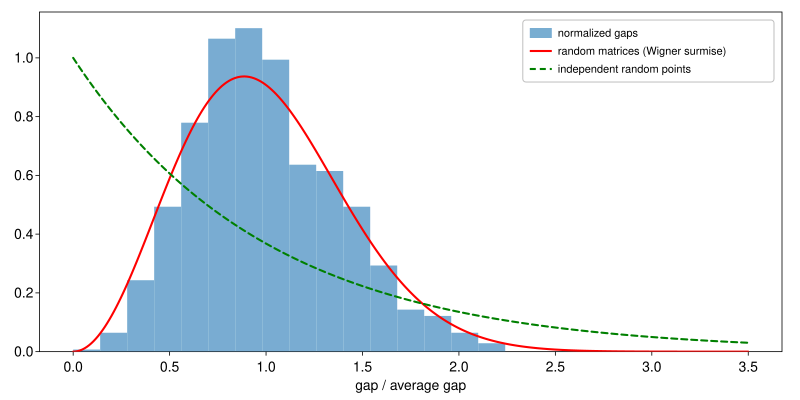

mean 0.999; smallest normalized gap 0.138


In [5]:
@interact
def zero_gaps(count=selector([100, 300, 1000], default=1000, label='zeros used'),
              bins=slider(10, 60, 5, 25, label='bins')):
    z = GAMMA[:count]
    s = np.diff(z) * np.log(z[:-1] / (2 * np.pi)) / (2 * np.pi)
    x = np.linspace(0, 3.5, 300)
    plt.figure(figsize=(8, 4))
    plt.hist(s, bins=bins, range=(0, 3.5), density=True, color='tab:blue', alpha=0.6, label='normalized gaps')
    plt.plot(x, 32 / np.pi**2 * x**2 * np.exp(-4 * x**2 / np.pi), 'r', label='random matrices (Wigner surmise)')
    plt.plot(x, np.exp(-x), 'g--', label='independent random points')
    plt.legend()
    plt.xlabel('gap / average gap')
    plt.show()
    print('mean %.3f; smallest normalized gap %.3f' % (s.mean(), s.min()))

## Things to try

1. The book shows histograms of the $\theta$'s modulo $2\pi$ and modulo $1$, which look flat ("no visible correlation between the $\theta_i$'s and translation"). Make them from `GAMMA % (2*np.pi)` and `GAMMA % 1`.
2. In section 2, at which $\theta_k$ is the left-over difference largest? Is it near a pair of unusually close zeros?
3. Compare the normalized gaps of the first $100$ zeros with those of zeros $900$ to $1000$. Does the fit to the random-matrix curve improve with height?

---
*Adapted and greatly expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. The zeros in `zeta_zeros_1000.txt` were computed with mpmath. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*